In [78]:
import pandas as pd
import numpy as np

In [79]:
df = pd.read_csv("titanic.csv")
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Cabin     204 non-null    str  
 1   Ticket    891 non-null    str  
 2   number    891 non-null    str  
 3   Survived  891 non-null    int64
dtypes: int64(1), str(3)
memory usage: 35.5 KB


In [81]:
df.describe() 

,Survived
count,891.000000
mean,0.383838
std,0.486592
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [82]:
df.isnull().sum()

Cabin       687
Ticket        0
number        0
Survived      0
dtype: int64

In [83]:
df.duplicated().sum()

24

In [84]:
df["number"].unique()

<ArrowStringArray>
['5', '3', '6', 'A', '2', '1', '4']
Length: 7, dtype: str

Text(0.5, 1.0, 'Passengers travelling with')

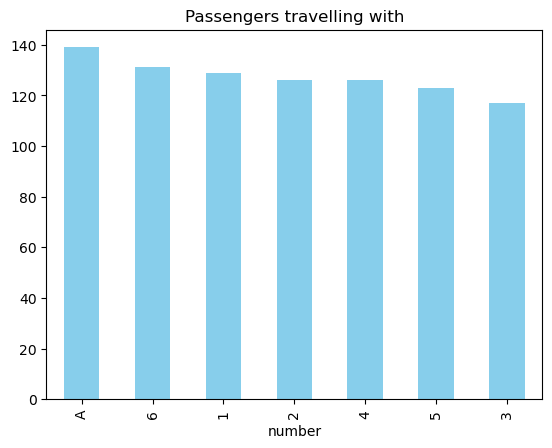

In [85]:
fig = df["number"].value_counts().plot(kind = "bar",color='skyblue')
fig.set_title("Passengers travelling with")

### extract numerical part


In [86]:
# extract numerical part
df["number_numerical"] = pd.to_numeric(df["number"], errors = "coerce", downcast="integer")

### extract categorical part

In [87]:
# extract categorical part

df["number_categorical"] = np.where(df["number_numerical"].isnull(), df["number"],np.nan)
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [88]:
df["Cabin"].unique()

<ArrowStringArray>
[          nan,         'C85',        'C123',         'E46',          'G6',
        'C103',         'D56',          'A6', 'C23 C25 C27',         'B78',
 ...
        'B102',         'B69',         'E49',         'C47',         'D28',
         'E17',         'A24',         'C50',         'B42',        'C148']
Length: 148, dtype: str

In [89]:
df["Ticket"].unique()

<ArrowStringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C.A./SOTON 34068',  'SOTON/OQ 392076',
           '211536',           '112053',           '111369',
           '370376']
Length: 681, dtype: str

In [90]:
df["Cabin_num"] = df['Cabin'].str.extract("(\d+)") # captures numerical part

In [91]:
df["Cabin_cat"] = df["Cabin"].str[0] # captures Categorical part

In [92]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,Cabin_num,Cabin_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN
1,C85,PC 17599,3,1,3.0,NaN,85,C
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN
3,C123,113803,3,1,3.0,NaN,123,C
4,NaN,373450,A,0,NaN,A,NaN,NaN


<Axes: xlabel='Cabin_cat'>

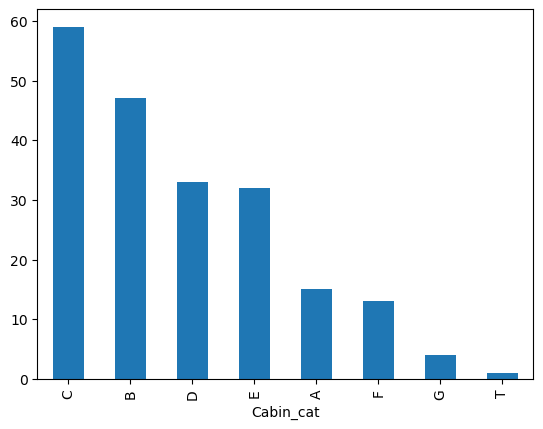

In [93]:
df["Cabin_cat"].value_counts().plot(kind="bar")

### extract the last bit of ticket as number

In [114]:
df["Ticket"].unique()

<ArrowStringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C.A./SOTON 34068',  'SOTON/OQ 392076',
           '211536',           '112053',           '111369',
           '370376']
Length: 681, dtype: str

In [111]:
# extract the last bit of ticket as number

# =======================================================
# df['ticket_num'] = df['Ticket'].str.split().str[-1]
# =======================================================

df["Ticket_num"] = df["Ticket"].apply(lambda s:s.split()[-1])
df["Ticket_num"] = pd.to_numeric(df["Ticket_num"], errors="coerce",downcast="integer") # convert into numerical

df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,Cabin_num,Cabin_cat,Ticket_num
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,21171.0
1,C85,PC 17599,3,1,3.0,NaN,85,C,17599.0
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,3101282.0
3,C123,113803,3,1,3.0,NaN,123,C,113803.0
4,NaN,373450,A,0,NaN,A,NaN,NaN,373450.0


In [117]:
# extract the first part of ticket as category

df["Ticket_cat"] = df["Ticket"].apply(lambda s: s.split()[0] if len(s.split()) > 1 else np.nan)


df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,Cabin_num,Cabin_cat,Ticket_num,Ticket_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,21171.0,A/5
1,C85,PC 17599,3,1,3.0,NaN,85,C,17599.0,PC
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,3101282.0,STON/O2.
3,C123,113803,3,1,3.0,NaN,123,C,113803.0,NaN
4,NaN,373450,A,0,NaN,A,NaN,NaN,373450.0,NaN
